# Advanced solution example: Solution in a Leaky, confined aquifer

In [1]:
# GEOSCI-627 Class 14

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

# The Hantush-Jacob Solution

The Hantush-Jacob Solution represents the solution to the 2-D (confined) groundwater flow equation, but with the addition of a source term representing leakage from an overlying aquifer. The leakage is represented as being proportional to the drawdown within the confined aquifer. In other words, as larger drawdowns are experienced from the confined aquifer, more leakage occurs accross the confining unit.


In [2]:
def WellFunc(u):
    Wu = sp.special.exp1(u)
    return Wu

def Theis_sol(Q, T, S, r, t, h_init):
    # Integral term for the Hantush well function
    u = (S*r**2)/(4*T*t)
    Wu = WellFunc(u)
    #the np.where function is used to return a drawdown of 0 before t = 0
    h = np.where(u > 0, -Q/(4*np.pi*T)*Wu + h_init, h_init)
    return h

def Hantush_integrand(y, r, B):
    # Integral term for the Hantush well function
    x = np.exp(-y - r**2 / (4. * B**2 * y)) / y
    return x

def Hantush_well_func(u, r, B):
    # Hantush well function
    x, _ = quad(lambda y: Hantush_integrand(y,r,B),u,np.inf)
    return x

def Hantush_sol(Q, T, S, r, t, L, h_init):
    B = np.sqrt(T*L)
    h = np.zeros(len(t))
    for i, t in enumerate(t):
        u = r**2 * S / (4 * T*t)
        h[i] = np.where(u > 0, -Q/(4 * np.pi * T)*Hantush_well_func(u,r,B) + h_init, h_init)
    return h

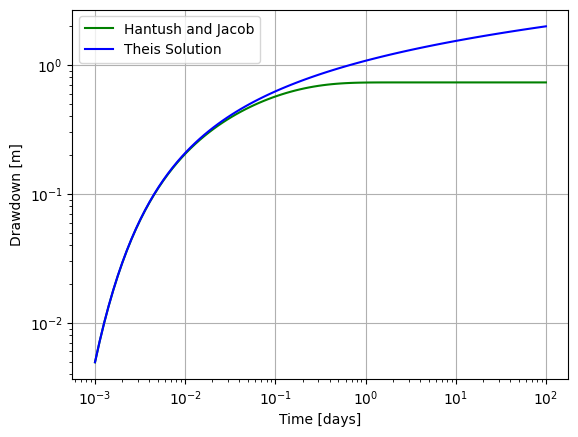

In [3]:
#Plotting of drawdown curves, comparing drawdown in a fully confined aquifer
# vs. drawdown in a leaky confined aquifer

#Pumping, aquifer, and confining unit properties
Q = 25 # m^3/day
K_aq = 1 #m/day
Ss_aq = 1e-6 # 1/m
b_aq = 10 # m
# thickness of confining layer
b_cf = 3 # m
K_cf = 1e-4 # m/day
h_init = 30

#Derived properties, needed for model inputs
T = K_aq*b_aq #Aquifer transmissivity
S = Ss_aq*b_aq #Aquifer specific storage
L = b_cf/K_cf #Confining unit "leakance"

t = np.logspace(-3, 2, 100)
r = 100

fig, ax = plt.subplots()
plt.plot(t, h_init - Hantush_sol(Q, T, S, r, t, L, h_init), color='g', label='Hantush and Jacob')
plt.plot(t, h_init - Theis_sol(Q,T,S,r,t, h_init), color='b', label='Theis Solution')

# format plot
plt.grid(True)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time [days]')
plt.ylabel('Drawdown [m]')
plt.legend()
plt.show()

## Questions to try

1. Try plotting the Hantush-Jacob solution for different values of the aquitard hydraulic conductivity. What happens as the aquitard gets more or less permeable?
2. Using a value of 1e-4 for `k_cf`, try looking at observation wells at a number of different distances. For the case of a leaky cofining unit, When does the cone of depression seem to stabilize across all observation wells?  